# Lab | Time Series Analysis

## Before your start:
- Read the README.md file
- Comment as much as you can and use the resources (README.md file)
- Happy learning!

In [22]:
# Import numpy and pandas
import numpy as np
import pandas as pd

## Challenge 1 - Loading and Evaluating The Data

In this lab, we will look at a dataset of sensor data from a cellular phone. The phone was carried in the subject's pocket for a few minutes while they walked around.

To load the data, run the code below.

In [23]:
# Run this code:

sensor = pd.read_csv('../data/sub_1.csv')
sensor.drop(columns=['Unnamed: 0'], inplace=True)

Examine the data using the `head` function.

In [24]:
# Your code here:
sensor.head()

,attitude.roll,attitude.pitch,attitude.yaw,gravity.x,gravity.y,gravity.z,rotationRate.x,rotationRate.y,rotationRate.z,userAcceleration.x,userAcceleration.y,userAcceleration.z
0,1.528132,-0.733896,0.696372,0.741895,0.669768,-0.031672,0.316738,0.778180,1.082764,0.294894,-0.184493,0.377542
1,1.527992,-0.716987,0.677762,0.753099,0.657116,-0.032255,0.842032,0.424446,0.643574,0.219405,0.035846,0.114866
2,1.527765,-0.706999,0.670951,0.759611,0.649555,-0.032707,-0.138143,-0.040741,0.343563,0.010714,0.134701,-0.167808
3,1.516768,-0.704678,0.675735,0.760709,0.647788,-0.041140,-0.025005,-1.048717,0.035860,-0.008389,0.136788,0.094958
4,1.493941,-0.703918,0.672994,0.760062,0.647210,-0.058530,0.114253,-0.912890,0.047341,0.199441,0.353996,-0.044299


Check whether there is any missing data. If there is any missing data, remove the rows containing missing data.

In [25]:
# Your code here:
sensor.isna().mean()
# no missing data

attitude.roll         0.0
attitude.pitch        0.0
attitude.yaw          0.0
gravity.x             0.0
gravity.y             0.0
gravity.z             0.0
rotationRate.x        0.0
rotationRate.y        0.0
rotationRate.z        0.0
userAcceleration.x    0.0
userAcceleration.y    0.0
userAcceleration.z    0.0
dtype: float64

How many rows and columns are in our data?

In [26]:
# Your code here:
sensor.shape


(1751, 12)

To perform time series analysis on the data, we must change the index from a range index to a time series index. In the cell below, create a time series index using the `pd.date_range` function. Create a time series index starting at 1/1/2018 00:00:00 and ending at 1/1/2018 00:29:10. The number of periods is equal to the number of rows in `sensor`. The frequency should be set to `infer`.

In [27]:
# Your code here:
sensor["date"] = pd.date_range("2018-01-01", "2018-01-01 00:29:10", freq="S")
sensor.tail()

C:\Users\Friedrich\AppData\Local\Temp\ipykernel_10024\2046738057.py:2: FutureWarning: 'S' is deprecated and will be removed in a future version, please use 's' instead.
  sensor["date"] = pd.date_range("2018-01-01", "2018-01-01 00:29:10", freq="S")


,attitude.roll,attitude.pitch,attitude.yaw,gravity.x,gravity.y,gravity.z,rotationRate.x,rotationRate.y,rotationRate.z,userAcceleration.x,userAcceleration.y,userAcceleration.z,date
1746,1.797120,-0.562324,2.445889,0.824443,0.533154,0.189844,-0.123211,0.909536,-0.379757,-0.268367,0.006733,-0.064874,2018-01-01 00:29:06
1747,1.814297,-0.569719,2.449655,0.817212,0.539396,0.203020,-0.057641,0.723118,-0.437812,-0.102444,-0.060666,-0.229738,2018-01-01 00:29:07
1748,1.830821,-0.578367,2.447967,0.809207,0.546658,0.215288,0.343238,0.997236,-0.338155,-0.085590,-0.030209,-0.087740,2018-01-01 00:29:08
1749,1.849557,-0.586962,2.439458,0.800485,0.553834,0.229110,0.470144,1.227937,-0.332223,-0.048105,0.029555,0.060441,2018-01-01 00:29:09
1750,1.869375,-0.596783,2.433775,0.790551,0.561984,0.243315,0.291873,1.102207,-0.436925,-0.065011,-0.042575,0.046052,2018-01-01 00:29:10


Assign the time series index to the dataframe's index.

In [ ]:
# Your code here:

sensor.set_index("date")

,attitude.roll,attitude.pitch,attitude.yaw,gravity.x,gravity.y,gravity.z,rotationRate.x,rotationRate.y,rotationRate.z,userAcceleration.x,userAcceleration.y,userAcceleration.z
date,,,,,,,,,,,,
2018-01-01 00:00:00,1.528132,-0.733896,0.696372,0.741895,0.669768,-0.031672,0.316738,0.778180,1.082764,0.294894,-0.184493,0.377542
2018-01-01 00:00:01,1.527992,-0.716987,0.677762,0.753099,0.657116,-0.032255,0.842032,0.424446,0.643574,0.219405,0.035846,0.114866
2018-01-01 00:00:02,1.527765,-0.706999,0.670951,0.759611,0.649555,-0.032707,-0.138143,-0.040741,0.343563,0.010714,0.134701,-0.167808
2018-01-01 00:00:03,1.516768,-0.704678,0.675735,0.760709,0.647788,-0.041140,-0.025005,-1.048717,0.035860,-0.008389,0.136788,0.094958
2018-01-01 00:00:04,1.493941,-0.703918,0.672994,0.760062,0.647210,-0.058530,0.114253,-0.912890,0.047341,0.199441,0.353996,-0.044299
...,...,...,...,...,...,...,...,...,...,...,...,...
2018-01-01 00:29:06,1.797120,-0.562324,2.445889,0.824443,0.533154,0.189844,-0.123211,0.909536,-0.379757,-0.268367,0.006733,-0.064874
2018-01-01 00:29:07,1.814297,-0.569719,2.449655,0.817212,0.539396,0.203020,-0.057641,0.723118,-0.437812,-0.102444,-0.060666,-0.229738
2018-01-01 00:29:08,1.830821,-0.578367,2.447967,0.809207,0.546658,0.215288,0.343238,0.997236,-0.338155,-0.085590,-0.030209,-0.087740


Our next step is to decompose the time series and evaluate the patterns in the data. Load the `statsmodels.api` submodule and plot the decomposed plot of `userAcceleration.x`. Set `freq=60` in the `seasonal_decompose` function. Your graph should look like the one below.

![time series decomposition](./images/tsa_decompose.png)

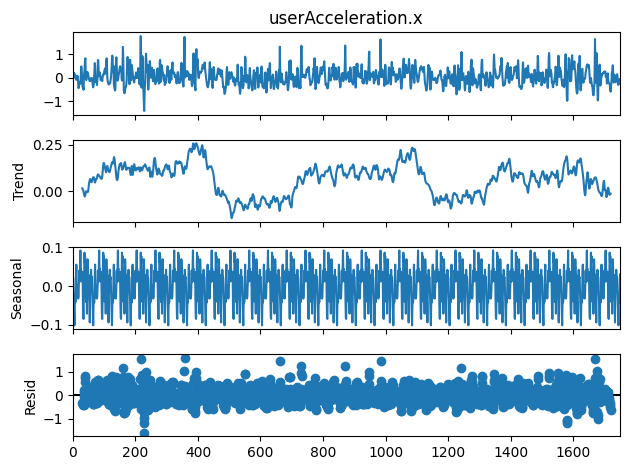

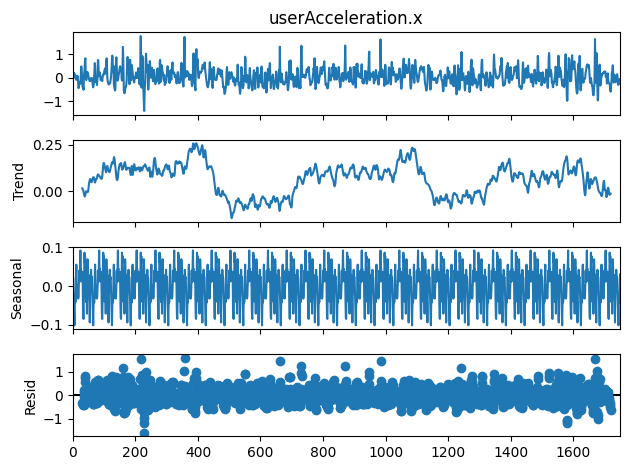

In [43]:
# Your code here:
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose

# Perform additive decomposition (period=60 → 1-minute cycle if freq=1s)
decomposition_add = seasonal_decompose(sensor["userAcceleration.x"], model='additive', period=60)

# Plot decomposition
decomposition_add.plot()


Plot the decomposed time series of `rotationRate.x` also with a frequency of 60.

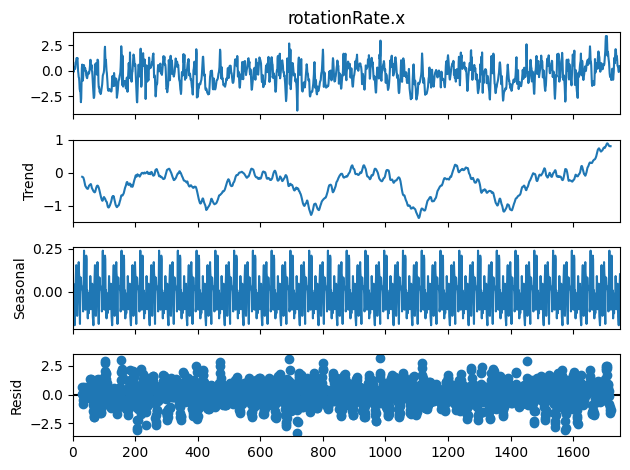

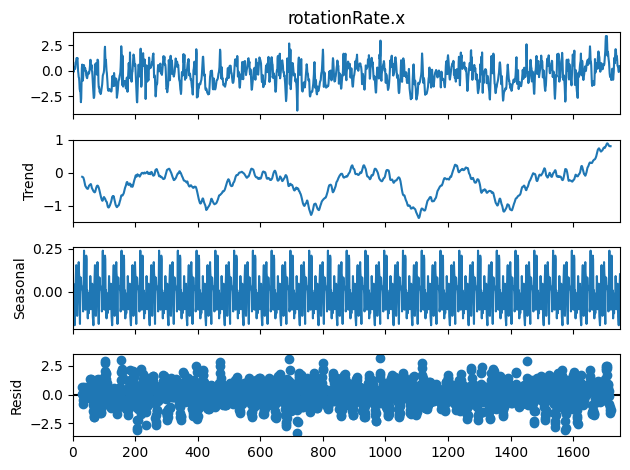

In [45]:
# Your code here:
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose

# Perform additive decomposition (period=60 → 1-minute cycle if freq=1s)
decomposition_add = seasonal_decompose(sensor["rotationRate.x"], model='additive', period=60)

# Plot decomposition
decomposition_add.plot()

## Challenge 2 - Modelling the Data

To model our data, we should look at a few assumptions. First, let's plot the `lag_plot` to detect any autocorrelation. Do this for `userAcceleration.x`

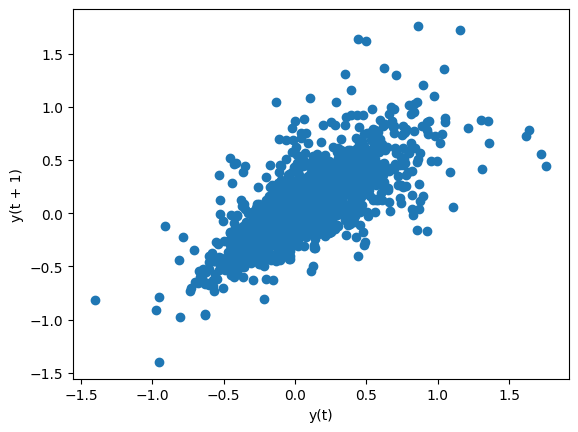

In [49]:
# Your code here:
from pandas.plotting import lag_plot
import matplotlib.pyplot as plt

# lag plot -> a scatter plot where each point is (X[t], X[t+1]), showing autocorrelation visually.
lag_plot(sensor["userAcceleration.x"])
plt.show()

Create a lag plot for `rotationRate.x`

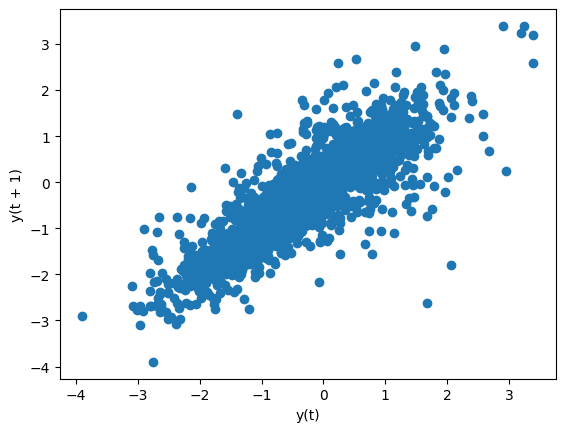

In [50]:
# Your code here:

lag_plot(sensor["rotationRate.x"])
plt.show()

What are your conclusions from both visualizations?

In [ ]:
# Your conclusions here:
"""
1. Random Cloud (No Pattern)
If the points look like a random scatter, with no visible structure, the time series is random / white noise.
-> Means little to no correlation between X[t] and X[t-1].

2. Straight Line (Positive Slope)
If the points cluster along a diagonal line (bottom-left → top-right), that shows a strong positive autocorrelation.
-> High values tend to follow high values, and low values follow low values.
Example: stock prices, slow-moving trends.

3. Straight Line (Negative Slope)
If the points cluster along a line with negative slope (top-left → bottom-right), that’s negative autocorrelation.
-> High values are followed by low values, and vice versa (oscillating behavior).

4. Curved / Other Shapes
If you see curves or repeating structures, that can indicate nonlinear relationships or seasonality.
->  Example: a circular/elliptical shape often means a periodic (cyclical) pattern.

---------------------------------------------------------------------------------

both lagplots resemble a tendency to a diagonal line (bottom-left → top-right)
This indicates that there is a positive autocorrelation.
"""


The next step will be to test both variables for stationarity. Perform the Augmented Dickey Fuller test on both variables below.

In [ ]:
# Your code here:

from statsmodels.tsa.stattools import adfuller

result = adfuller(sensor["rotationRate.x"], autolag='AIC')
print("userAcceleration.x")
print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Lags used:", result[2])
print("Number of observations:", result[3])
print("Critical Values:", result[4])


result = adfuller(sensor["rotationRate.x"], autolag='AIC')
print("-----------------------")
print("rotationRate.x:")
print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Lags used:", result[2])
print("Number of observations:", result[3])
print("Critical Values:", result[4])

"""
userAcceleration.x
ADF Statistic: -5.269860625086409
p-value: 6.320230335912605e-06
Lags used: 25
Number of observations: 1725

----------------------------------------------
rotationRate.x:
ADF Statistic: -5.269860625086409
p-value: 6.320230335912605e-06
Lags used: 25
Number of observations: 1725

Null hypothesis (H₀): Series has a unit root (not stationary).
Alternative (H₁): Series is stationary.
Look at the p-value:
    p-value ≤ 0.05 → reject H₀ → stationary
    p-value > 0.05 → fail to reject H₀ → non-stationary

----------------------------------------------
Both p-values are below 0.05 → reject H₀ → stationary

"""

userAcceleration.x
ADF Statistic: -5.269860625086409
p-value: 6.320230335912605e-06
Lags used: 25
Number of observations: 1725
Critical Values: {'1%': np.float64(-3.4341465551936534), '5%': np.float64(-2.863216966926812), '10%': np.float64(-2.567662770090317)}
-----------------------
rotationRate.x:
ADF Statistic: -5.269860625086409
p-value: 6.320230335912605e-06
Lags used: 25
Number of observations: 1725
Critical Values: {'1%': np.float64(-3.4341465551936534), '5%': np.float64(-2.863216966926812), '10%': np.float64(-2.567662770090317)}


What are your conclusions from this test?

In [ ]:
# Your conclusions here:
"""
Both p-values are below 0.05 → reject H₀ → stationary

"""


Finally, we'll create an ARMA model for `userAcceleration.x`. Load the `ARMA` function from `statsmodels`. The order of the model is (2, 1). Split the data to train and test. Use the last 10 observations as the test set and all other observations as the training set. 

c:\Users\Friedrich\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)
c:\Users\Friedrich\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)
c:\Users\Friedrich\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0637      0.016      3.994      0.000       0.032       0.095
ar.L1          0.9882      0.036     27.630      0.000       0.918       1.058
ar.L2         -0.3788      0.033    -11.637      0.000      -0.443      -0.315
ma.L1          0.1824      0.039      4.643      0.000       0.105       0.259
sigma2         0.0381      0.001     46.070      0.000       0.036       0.040


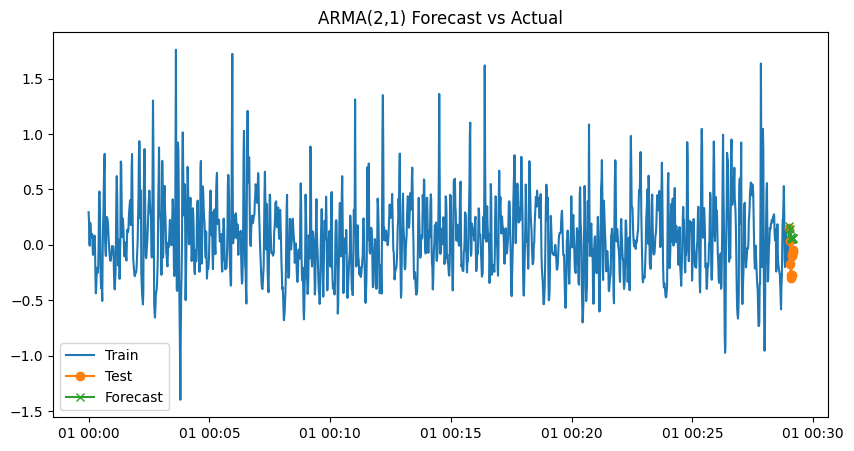

In [60]:
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt


# Split into train and test sets
train = sensor["userAcceleration.x"][:-10]  # all except last 10
test = sensor["userAcceleration.x"][-10:]   # last 10 observations

# Create ARMA model (order=(2,1) → AR=2, MA=1, d=0 for ARMA)
arma_model = ARIMA(train, order=(2, 0, 1))  # ARMA: d=0
arma_results = arma_model.fit()

# Print model summary
print(arma_results.summary().tables[1])

# Forecast the next 10 observations
forecast = arma_results.forecast(steps=10)

# Compare forecast vs actual
plt.figure(figsize=(10,5))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Test", marker='o')
plt.plot(test.index, forecast, label="Forecast", marker='x')
plt.legend()
plt.title("ARMA(2,1) Forecast vs Actual")

plt.show()


To compare our predictions with the observed data, we can compute the RMSE (Root Mean Squared Error) from the submodule `statsmodels.tools.eval_measures`. You can read more about this function [here](https://www.statsmodels.org/dev/generated/statsmodels.tools.eval_measures.rmse.html). Compute the RMSE for the last 10 rows of the data by comparing the observed and predicted data for the `userAcceleration.x` column.

In [63]:
# Your code here:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(test, forecast)
# Take square root to get RMSE
rmse = np.sqrt(mse)
print("RMSE:", rmse)



RMSE: 0.22529160449986013
